## Importing lib

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading dataset

In [2]:
df = pd.read_csv("Walmart.csv")
df

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
0,1,WALM003,San Antonio,Health and beauty,$74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48
1,2,WALM048,Harlingen,Electronic accessories,$15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48
2,3,WALM067,Haltom City,Home and lifestyle,$46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33
3,4,WALM064,Bedford,Health and beauty,$58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33
4,5,WALM013,Irving,Sports and travel,$86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48
...,...,...,...,...,...,...,...,...,...,...,...
10046,9996,WALM056,Rowlett,Fashion accessories,$37,3.0,03/08/23,10:10:00,Cash,3.0,0.33
10047,9997,WALM030,Richardson,Home and lifestyle,$58,2.0,22/02/21,14:20:00,Cash,7.0,0.48
10048,9998,WALM050,Victoria,Fashion accessories,$52,3.0,15/06/23,16:00:00,Credit card,4.0,0.48
10049,9999,WALM032,Tyler,Home and lifestyle,$79,2.0,25/02/21,12:25:00,Cash,7.0,0.48


In [3]:
df.shape

(10051, 11)

In [4]:
df.describe()

,invoice_id,quantity,rating,profit_margin
count,10051.000000,10020.000000,10051.000000,10051.000000
mean,5025.741220,2.353493,5.825659,0.393791
std,2901.174372,1.602658,1.763991,0.090669
min,1.000000,1.000000,3.000000,0.180000
25%,2513.500000,1.000000,4.000000,0.330000
50%,5026.000000,2.000000,6.000000,0.330000
75%,7538.500000,3.000000,7.000000,0.480000
max,10000.000000,10.000000,10.000000,0.570000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10051 entries, 0 to 10050
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_id      10051 non-null  int64  
 1   Branch          10051 non-null  object 
 2   City            10051 non-null  object 
 3   category        10051 non-null  object 
 4   unit_price      10020 non-null  object 
 5   quantity        10020 non-null  float64
 6   date            10051 non-null  object 
 7   time            10051 non-null  object 
 8   payment_method  10051 non-null  object 
 9   rating          10051 non-null  float64
 10  profit_margin   10051 non-null  float64
dtypes: float64(3), int64(1), object(7)
memory usage: 863.9+ KB


In [6]:
# Datatype changing of column "DateTime"
df['DateTime'] = pd.to_datetime(df['date'] + ' ' + df['time'], format='%d/%m/%y %H:%M:%S')
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime
0,1,WALM003,San Antonio,Health and beauty,$74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,2019-01-05 13:08:00
1,2,WALM048,Harlingen,Electronic accessories,$15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,2019-03-08 10:29:00
2,3,WALM067,Haltom City,Home and lifestyle,$46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,2019-03-03 13:23:00
3,4,WALM064,Bedford,Health and beauty,$58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,2019-01-27 20:33:00
4,5,WALM013,Irving,Sports and travel,$86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,2019-02-08 10:37:00


In [7]:
df.isnull().sum()

invoice_id         0
Branch             0
City               0
category           0
unit_price        31
quantity          31
date               0
time               0
payment_method     0
rating             0
profit_margin      0
DateTime           0
dtype: int64

In [8]:
df[df['unit_price'].isnull()]

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime
1892,1893,WALM024,Carrollton,Home and lifestyle,NaN,NaN,09/06/23,16:09:00,Ewallet,9.0,0.48,2023-06-09 16:09:00
1893,1894,WALM009,Plano,Fashion accessories,NaN,NaN,02/08/22,22:11:00,Ewallet,4.0,0.48,2022-08-02 22:11:00
1894,1895,WALM010,Laredo,Home and lifestyle,NaN,NaN,01/08/23,12:06:00,Ewallet,4.0,0.48,2023-08-01 12:06:00
1895,1896,WALM069,Rockwall,Fashion accessories,NaN,NaN,21/07/23,15:49:00,Ewallet,4.0,0.33,2023-07-21 15:49:00
1896,1897,WALM093,Angleton,Home and lifestyle,NaN,NaN,15/05/22,12:36:00,Ewallet,9.0,0.33,2022-05-15 12:36:00
1897,1898,WALM098,Mineral Wells,Fashion accessories,NaN,NaN,01/11/23,10:08:00,Ewallet,4.0,0.18,2023-11-01 10:08:00
1898,1899,WALM009,Plano,Home and lifestyle,NaN,NaN,01/10/21,13:05:00,Ewallet,6.0,0.48,2021-10-01 13:05:00
1899,1900,WALM071,Lufkin,Fashion accessories,NaN,NaN,19/05/21,8:36:00,Ewallet,7.0,0.33,2021-05-19 08:36:00
1900,1901,WALM090,Brownwood,Home and lifestyle,NaN,NaN,13/02/21,14:50:00,Ewallet,8.0,0.33,2021-02-13 14:50:00
1901,1902,WALM067,Haltom City,Fashion accessories,NaN,NaN,15/05/22,19:20:00,Ewallet,8.0,0.33,2022-05-15 19:20:00


In [9]:
# Droping NUll values 
df.dropna(inplace=True)

#### Dulicated values

In [10]:
df.duplicated().sum()

np.int64(51)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
# Removal of "$"
df['unit_price'] = df['unit_price'].str.strip('$').astype(float)
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,2019-01-05 13:08:00
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,2019-03-08 10:29:00
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,2019-03-03 13:23:00
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,2019-01-27 20:33:00
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,2019-02-08 10:37:00


##### Feature Engineering

In [13]:
# Creating a new column 'sales_price' using unit_price and quantity
df['sales_price'] = df['unit_price'] * df['quantity']
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime,sales_price
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,2019-01-05 13:08:00,522.83
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,2019-03-08 10:29:00,76.40
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,2019-03-03 13:23:00,324.31
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,2019-01-27 20:33:00,465.76
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,2019-02-08 10:37:00,604.17


In [14]:
#creating a profit column
df['profit'] = df['unit_price']*df['quantity']*df['profit_margin']
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime,sales_price,profit
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,2019-01-05 13:08:00,522.83,250.9584
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,2019-03-08 10:29:00,76.40,36.6720
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,2019-03-03 13:23:00,324.31,107.0223
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,2019-01-27 20:33:00,465.76,153.7008
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,2019-02-08 10:37:00,604.17,290.0016


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9969 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   invoice_id      9969 non-null   int64         
 1   Branch          9969 non-null   object        
 2   City            9969 non-null   object        
 3   category        9969 non-null   object        
 4   unit_price      9969 non-null   float64       
 5   quantity        9969 non-null   float64       
 6   date            9969 non-null   object        
 7   time            9969 non-null   object        
 8   payment_method  9969 non-null   object        
 9   rating          9969 non-null   float64       
 10  profit_margin   9969 non-null   float64       
 11  DateTime        9969 non-null   datetime64[ns]
 12  sales_price     9969 non-null   float64       
 13  profit          9969 non-null   float64       
dtypes: datetime64[ns](1), float64(6), int64(1), object(6)
memory 

In [16]:
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,DateTime,sales_price,profit
0,1,WALM003,San Antonio,Health and beauty,74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48,2019-01-05 13:08:00,522.83,250.9584
1,2,WALM048,Harlingen,Electronic accessories,15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48,2019-03-08 10:29:00,76.40,36.6720
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33,2019-03-03 13:23:00,324.31,107.0223
3,4,WALM064,Bedford,Health and beauty,58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33,2019-01-27 20:33:00,465.76,153.7008
4,5,WALM013,Irving,Sports and travel,86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48,2019-02-08 10:37:00,604.17,290.0016


###### Saving the cleaned file

In [20]:
df.to_csv("walmart_cleaned.csv")

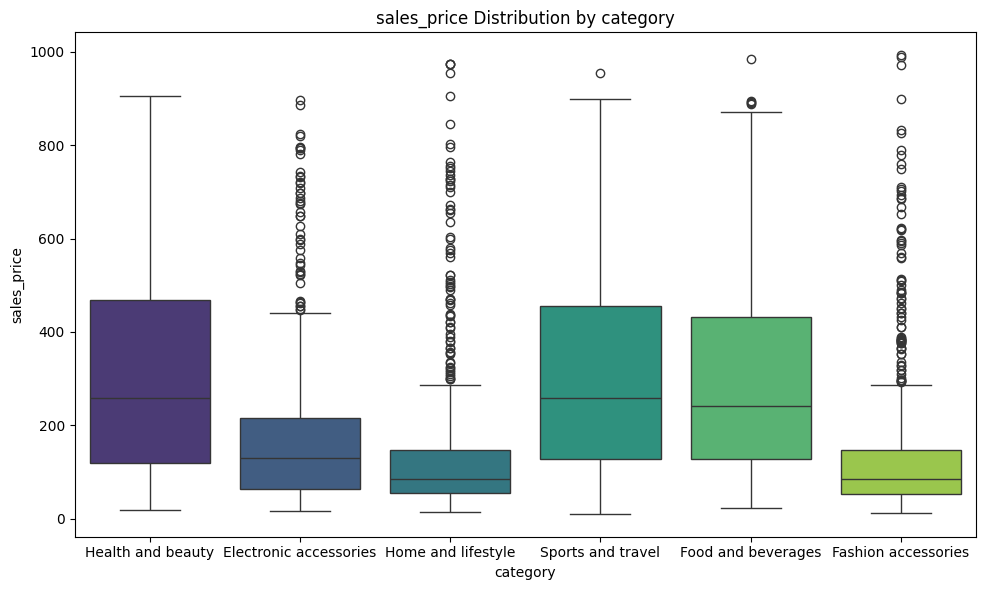

In [18]:
# seles values distribution across different category
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='category', y='sales_price', hue='category', palette='viridis', legend=False)
plt.title('sales_price Distribution by category')
plt.tight_layout()
plt.show()

#### Connect to DBMS

In [19]:
!pip install sqlalchemy psycopg2-binary

from sqlalchemy import create_engine

# --- Database Connection Parameters --- #
# Replace with your actual PostgreSQL credentials
db_user = 'postgres'
db_password = 'password'
db_host = 'localhost'
db_port = '5432'
db_name = 'walmart_db'

# Create the SQLAlchemy engine
engine = create_engine(f'postgresql+psycopg2://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}')

# Define the table name
table_name = 'walmart'

# DataFrame to PostgreSQL
df.to_sql(table_name, engine, if_exists='replace', index=False)

print(f"DataFrame successfully written to PostgreSQL table '{table_name}' in database '{db_name}'")

DataFrame successfully written to PostgreSQL table 'walmart' in database 'walmart_db'
